# 01 · The targets: the Belgian standard chart

**The question this step answers:** *what* do we map onto? Every company account in D1 ends up in one of the **190 three-digit groups** of the Belgian standard chart (PCMN, the minimum standard chart under Belgian law). This notebook shows what those 190 groups are and how the code reads them.

**Where it sits in the pipeline:** it comes first. The noise rules, the fake companies, the embeddings and every mapping method all start from this list.

**The code:** `src/d1/datagen/standard_chart.py` → `load_standard_chart(path, expected=190)`.

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

## 1. One group, as the code sees it

Take group **440**. After loading, it is one record with its names in three languages, its parent group and its class:

In [2]:
a = by_code["440"]
display(pd.Series(a.model_dump(), name="group 440").to_frame())

,group 440
code,440
code_end,NaN
parent_code,44
class_code,4
name_en,Suppliers
name_fr,Fournisseurs
name_nl,Leveranciers
parent_name_en,Trade Debts
class_name_en,Amounts Receivable Within One Year


- **`code`** is the target a mapping method must predict ("440").
- **`name_en` / `name_nl` / `name_fr`**: one name per language, so a Dutch, French or English company can be matched.
- **`parent_name_en`** and **`class_name_en`** say where the group sits. 440 is part of 44 *Trade Debts*, which is part of class 4 *Amounts Receivable and Payable Within One Year*. The embeddings and the XGBoost features use the parent later.

## 2. How the code gets there, step by step

The source is one file from Odoo, the open-source accounting software (`data/source/odoo_l10n_be/account.group-be.csv`, pinned to one exact version, LGPL-3 licence). It mixes three levels of rows:

In [3]:
raw = pd.read_csv(config.data.chart_path, dtype=str, keep_default_na=False)
raw["level"] = raw["code_prefix_start"].str.len().map({1: "1 digit: class", 2: "2 digits: parent", 3: "3 digits: group (target)"})
display(raw[raw["code_prefix_start"].isin(["4", "44", "440", "441"])][["code_prefix_start", "level", "name", "name@nl", "name@fr"]])
print(raw["level"].value_counts().to_string())

,code_prefix_start,level,name,name@nl,name@fr
86,4,1 digit: class,Amounts Receivable Within One Year,Vorderingen op ten hoogste één jaar,Créances à un an au plus
118,44,2 digits: parent,Trade Debts,Handelsschulden,Dettes commerciales
119,440,3 digits: group (target),Suppliers,Leveranciers,Fournisseurs
120,441,3 digits: group (target),Bills of Exchange Payable,Te betalen wissels,Effets à payer


level
3 digits: group (target)    190
2 digits: parent             55
1 digit: class                7


What `load_standard_chart` does with it:
1. **Read every row** and index it by its code.
2. **Keep only the 3-digit rows.** Those are the targets; the 1- and 2-digit rows are only used to look up names.
3. **For each group, look up its class** (first digit) and its **parent** (first two digits), and copy their English names onto the group.
4. **Check the count:** exactly 190, or loading fails. If the file ever changes, the experiment stops instead of silently predicting something else.

Two quirks of the real file are handled on the way:

In [4]:
quirks = pd.DataFrame([
    {"group": a.code, "quirk": f"covers a range up to {a.code_end}", "name": a.name_en} for a in chart if a.code_end
] + [
    {"group": a.code, "quirk": "no 2-digit parent row: parent name falls back to the class", "name": a.name_en}
    for a in chart if a.parent_code is None
])
display(quirks)

,group,quirk,name
0,164,covers a range up to 165,Provisions for Other Liabilities and Charges
1,550,covers a range up to 559,Cash at Bank - Credit Institutions
2,570,covers a range up to 577,Cash in Hand - Cash
3,657,covers a range up to 658,Miscellaneous Financial Charges
4,664,covers a range up to 667,Other Non-Recurring Operating Charges
5,700,covers a range up to 707,Sales and Services Rendered
6,743,covers a range up to 749,Miscellaneous Operating Income
7,756,covers a range up to 759,Miscellaneous Financial Income
8,764,covers a range up to 768,Other Non-Recurring Operating Income
9,132,no 2-digit parent row: parent name falls back to the class,Untaxed Reserves


## 3. What the 190 groups look like

Per class: how many groups each class holds. Class 6 (expenses) and class 4 (receivables and payables within one year) hold about half of all groups. That's also where most company accounts sit. The class names are Odoo's English names, cut short here.

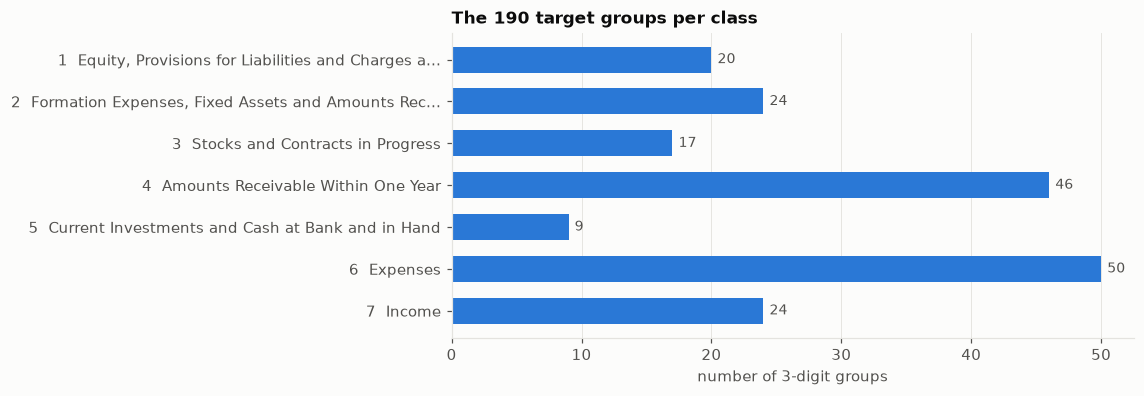

In [5]:
per_class = pd.Series(Counter(a.class_code for a in chart)).sort_index()
names = {a.class_code: a.class_name_en for a in chart}
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh([f"{c}  {names[c][:48]}{'…' if len(names[c]) > 48 else ''}" for c in per_class.index], per_class.values, color=SINGLE, height=0.62)
ax.bar_label(bars, padding=4, fontsize=9, color=INK_2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("number of 3-digit groups")
ax.set_title(f"The {len(chart)} target groups per class")
plt.show()

**Name lengths per language.** Standard names are long: about two thirds are over 30 characters in every language, Dutch slightly more often than French and English. That matters for one noise rule (notebook 02): old software with a 30-character name field cuts these names, and the cut-off part is often the word that tells two groups apart.

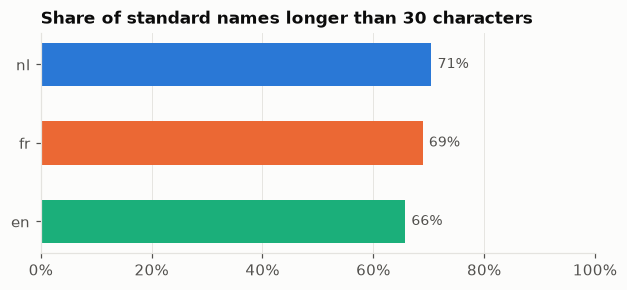

,nl,fr,en
mean,42.6,41.3,38.7
median,42.5,40.5,38.5
max,212.0,193.0,149.0


In [6]:
lengths = pd.DataFrame({lang: [len(a.name(lang)) for a in chart] for lang in ["nl", "fr", "en"]})
over = (lengths > 30).mean()
fig, ax = plt.subplots(figsize=(6.5, 2.6))
bars = ax.barh(list(over.index), over.values, color=[LANGUAGE_COLORS[l] for l in over.index], height=0.55)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in over.values], padding=4, fontsize=9, color=INK_2)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct())
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_title("Share of standard names longer than 30 characters")
plt.show()
display(lengths.describe().loc[["mean", "50%", "max"]].round(1).rename(index={"50%": "median"}))

## 4. Groups that share a name

Five English names occur twice. The same words mean different things on the balance sheet and in the income statement. "Provisions for Pensions" is the provision itself in 160, and the cost of adding to it in 635. That's why the text embedded for each group (notebook 07) includes the parent name: the parent tells the two apart.

In [7]:
twice = [n for n, k in Counter(a.name_en for a in chart).items() if k > 1]
display(pd.DataFrame([{"name": a.name_en, "group": a.code, "parent": a.parent_name_en} for a in chart if a.name_en in twice]).set_index(["name", "group"]))

,,parent
name,group,
Provisions for Pensions and Similar Obligations,160,Provisions and Deferred Taxes
Provisions for Major Repairs and Maintenance,162,Provisions and Deferred Taxes
Provisions for Environmental Obligations,163,Provisions and Deferred Taxes
Provisions for Pensions and Similar Obligations,635,"Depreciation, Amounts Written Off and Provisions for Risks and Charges"
Provisions for Major Repairs and Maintenance,636,"Depreciation, Amounts Written Off and Provisions for Risks and Charges"
Provisions for Environmental Obligations,637,"Depreciation, Amounts Written Off and Provisions for Risks and Charges"
Exchange Differences,654,Financial Charges
Foreign Currency Translation Differences,655,Financial Charges
Exchange Differences,754,Financial Income


## 5. What is *not* in the list

- **No 4- to 6-digit accounts.** Companies add their own detail below the 3-digit level, and the "right" answer at that depth depends on company policy. Mapping to 3 digits gives one clearly right answer per account.
- **Group 638 does not exist in this file.** Odoo's groups for class 63 stop at 637. The hand check of the test set (notebook 06) found one account, a reversal of a provision for a client dispute, that belongs in 638. No method can ever predict it. That's a limitation of the target list, stated in the model card.
- **No descriptions, only names.** Notebook 08 shows that this costs recall: bookkeepers write "wages" where the chart says "remuneration".

In [8]:
print("groups in class 63:", [a.code for a in chart if a.code.startswith("63")])

groups in class 63: ['630', '631', '632', '633', '634', '635', '636', '637']
